# 02 : Baseline and AutoML v0.1 (Step 2)
Owner: Enki. This notebook covers points 2 to 5 of step 2: the learning and testing plan, the baseline,
the benchmark from the literature and a first AutoML pipeline with standard algorithms.

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.append(str(Path("..") / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_validate, cross_val_predict, learning_curve
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from scipy.stats import loguniform, randint

from common import *
from evaluation import SCORING, ranking_metrics, recall_at_top
from models import get_model, save_best_params, BUILDERS
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
set_seed()
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(parents=True, exist_ok=True)

## 1. Learning and testing plan
* **Test set:** 20 % of the rows, stratified on `y`, `random_state=42`, made once by `code/step2_split.py`
  (`dataset/train.csv`, `dataset/test.csv`). It is only used in notebook 04, once, after every model has been chosen.
* **Validation:** 5-fold stratified cross-validation on the 80 % train set, to tune and compare the models.
* **No leakage:** encoding and scaling (`code/step2_preprocessing.py`) are inside a `Pipeline`, so in each fold they are fitted on the 4 training
  folds only. The cleaning of notebook 01 is row by row (no statistic computed on the whole data), so it can be
  done before the split. `duration` and `row_order` are not features.
* **Over/underfitting:** we compare the train score and the CV score, and we draw a learning curve.
* **Second test:** the data drifts in time, so notebook 04 also trains on the oldest 80 % and tests on the most
  recent 20 %.

In [2]:
df = load_clean()
train, test = random_split(df)
X_train, y_train = xy(train)
print("train:", X_train.shape, " test:", test.shape)
print("share of yes  all: %.4f  train: %.4f  test: %.4f" % (df.y.mean(), y_train.mean(), test.y.mean()))
print("row_order or duration in the features:", {"row_order", "duration"} & set(X_train.columns))
# keep the list of test rows, so everybody can check they use the same test set
test[["row_order"]].to_csv(RESULTS / "test_rows.csv", index=False)

train: (32940, 20)  test: (8236, 22)
share of yes  all: 0.1127  train: 0.1127  test: 0.1127
row_order or duration in the features: set()


## 2. What "doing nothing" gives: dummy model
The dummy model gives every client the same probability (the share of yes in the training folds).

In [3]:
cv = cv_folds()
rows = []
s = cross_validate(get_model("dummy"), X_train, y_train, cv=cv, scoring=SCORING)
rows.append({"model": "dummy", "cv_pr_auc": s["test_pr_auc"].mean(), "cv_pr_auc_std": s["test_pr_auc"].std(),
             "cv_roc_auc": s["test_roc_auc"].mean()})
pd.DataFrame(rows)

,model,cv_pr_auc,cv_pr_auc_std,cv_roc_auc
0,dummy,0.1127,6.0716e-05,0.5


## 3. Baseline: logistic regression
We tune two things with a grid search on the 5 folds, using PR-AUC:
* `C`, the inverse of the L2 regularisation strength. Small `C` = strong regularisation. It matters here because
  `euribor3m`, `emp.var.rate` and `nr.employed` are very correlated (VIF > 30 in notebook 01).
* `class_weight`: `None` or `"balanced"` (gives the yes rows 8 times more weight).

In [4]:
grid = {"model__C": [0.001, 0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]}
gs = GridSearchCV(get_model("logreg_baseline"), grid, cv=cv, scoring=SCORING, refit="pr_auc",
                  return_train_score=True, n_jobs=-1)
gs.fit(X_train, y_train)
res = pd.DataFrame(gs.cv_results_)
cols = ["param_model__C", "param_model__class_weight", "mean_train_pr_auc", "mean_test_pr_auc",
        "std_test_pr_auc", "mean_test_roc_auc"]
res[cols].sort_values("mean_test_pr_auc", ascending=False)

,param_model__C,param_model__class_weight,mean_train_pr_auc,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc
10,100.000,NaN,0.4574,0.4497,0.0059,0.7884
8,10.000,NaN,0.4574,0.4495,0.0058,0.7884
6,1.000,NaN,0.4573,0.4495,0.0058,0.7884
4,0.100,NaN,0.4558,0.4484,0.0056,0.7886
7,1.000,balanced,0.4518,0.4459,0.0064,0.7892
11,100.000,balanced,0.4517,0.4459,0.0065,0.7892
9,10.000,balanced,0.4516,0.4457,0.0065,0.7891
5,0.100,balanced,0.4508,0.4450,0.0057,0.7892
2,0.010,NaN,0.4462,0.4417,0.0106,0.7863
3,0.010,balanced,0.4418,0.4378,0.0083,0.7879


The score is almost flat for `C >= 0.1`: between `C = 0.1` and `C = 100` the CV PR-AUC only moves from
0.448 to 0.450, which is smaller than the standard deviation between folds (about 0.006). The best value of the
grid is `C = 100`, the last value we tried: taking it would mean choosing on noise, and choosing the weakest
regularisation. We use the **one standard error rule**: we keep the most regularised model whose
score is within one standard error (std / sqrt(5)) of the best one. It is more stable and less likely to overfit.

In [5]:
# one standard error rule: among the settings close enough to the best one, take the most regularised (smallest C)
best_i = gs.best_index_
se = res.loc[best_i, "std_test_pr_auc"] / np.sqrt(cv.get_n_splits())
ok = res[res.mean_test_pr_auc >= res.loc[best_i, "mean_test_pr_auc"] - se]
chosen = ok.sort_values(["param_model__C", "mean_test_pr_auc"], ascending=[True, False]).iloc[0]
params = {"model__C": float(chosen.param_model__C),
          "model__class_weight": None if pd.isna(chosen.param_model__class_weight) else chosen.param_model__class_weight}
print("grid best:", gs.best_params_, "PR-AUC %.4f" % gs.best_score_, "| threshold best - 1 SE: %.4f" % (gs.best_score_ - se))
print("chosen:", params, "PR-AUC %.4f" % chosen.mean_test_pr_auc)
save_best_params("logreg_baseline", params)

grid best: {'model__C': 100, 'model__class_weight': None} PR-AUC 0.4497 | threshold best - 1 SE: 0.4471
chosen: {'model__C': 0.1, 'model__class_weight': None} PR-AUC 0.4484


### Calibration of the probabilities
`class_weight="balanced"` changes the probabilities: the model thinks there are as many yes as no.
We compare the out-of-fold probabilities of both versions (same `C`) with the real share of yes.

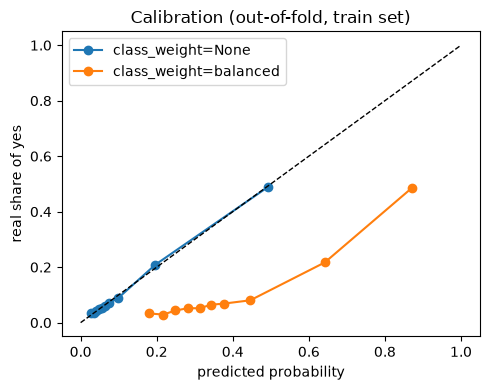

,class_weight,mean_proba,brier,pr_auc,roc_auc,recall_top20
0,None,0.1127,0.0788,0.4478,0.7884,0.6184
1,balanced,0.3920,0.1654,0.4448,0.7890,0.6244


In [6]:
best_C = params["model__C"]
fig, ax = plt.subplots(figsize=(5, 4))
cal_rows = []
for cw in [None, "balanced"]:
    m = get_model("logreg_baseline").set_params(model__C=best_C, model__class_weight=cw)
    p = cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    frac, mean_p = calibration_curve(y_train, p, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", label=f"class_weight={cw}")
    cal_rows.append({"class_weight": str(cw), "mean_proba": p.mean(), "brier": brier_score_loss(y_train, p),
                     **ranking_metrics(y_train, p)})
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("predicted probability"); ax.set_ylabel("real share of yes")
ax.set_title("Calibration (out-of-fold, train set)"); ax.legend(); plt.tight_layout()
plt.savefig(FIGURES / "logreg_calibration.png", dpi=150); plt.show()
pd.DataFrame(cal_rows)

Both versions rank the clients almost the same way (PR-AUC 0.448 vs 0.445, recall in the top 20 % 0.618 vs 0.624),
but with `"balanced"` the average predicted probability is 0.392 when the real share of yes is 0.113, and the
Brier score doubles (0.079 to 0.165). Since we want a ranking and maybe later a probability the bank can read,
we keep `class_weight=None`. The imbalance is handled by the metric (PR-AUC) and by the choice of the threshold
in notebook 04, not by reweighting.

### Overfitting or underfitting?

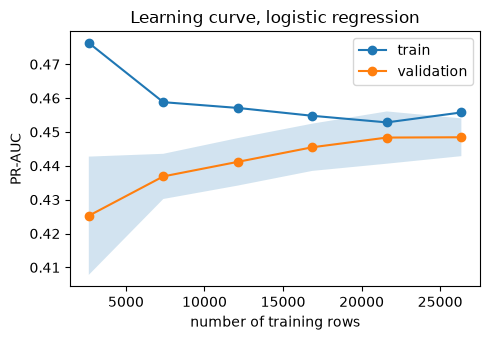

,n_rows,train,validation
0,2635,0.4763,0.4253
1,7378,0.4588,0.4369
2,12121,0.4571,0.4412
3,16865,0.4548,0.4455
4,21608,0.4528,0.4483
5,26352,0.4558,0.4484


In [7]:
sizes, tr, va = learning_curve(get_model("logreg_baseline"), X_train, y_train, cv=cv, scoring="average_precision",
                               train_sizes=np.linspace(0.1, 1, 6), n_jobs=-1, random_state=SEED, shuffle=True)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(sizes, tr.mean(1), marker="o", label="train"); ax.plot(sizes, va.mean(1), marker="o", label="validation")
ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.2)
ax.set_xlabel("number of training rows"); ax.set_ylabel("PR-AUC"); ax.set_title("Learning curve, logistic regression")
ax.legend(); plt.tight_layout(); plt.savefig(FIGURES / "logreg_learning_curve.png", dpi=150); plt.show()
pd.DataFrame({"n_rows": sizes, "train": tr.mean(1), "validation": va.mean(1)})

The train and validation curves get close (0.456 vs 0.448 with all the rows) and the validation score stops
improving after about 20,000 rows. There is no overfitting, the model is rather limited by its simplicity
(it can only draw a linear frontier): adding more data will not help much, a more flexible model might.

In [8]:
# what the baseline relies on (we do not read the 3 economic variables one by one, they are collinear)
best = get_model("logreg_baseline").fit(X_train, y_train)
names = best.named_steps["prep"].get_feature_names_out()
coef = pd.Series(best.named_steps["model"].coef_[0], index=names).sort_values()
pd.concat([coef.head(6), coef.tail(6)])

emp.var.rate        -1.3293
month_may           -0.5896
poutcome_failure    -0.4982
month_nov           -0.4371
contact_telephone   -0.3498
month_jun           -0.3162
job_retired          0.2740
month_dec            0.3339
poutcome_success     0.4700
cons.price.idx       0.6702
prev_contacted       0.8832
month_mar            1.0045
dtype: float64

The signs make sense: calls in March and December work better, calls in May (the month with the most calls) and
to landline phones work worse, a client already contacted in a previous campaign is more likely to say yes
(`prev_contacted`, `poutcome_success`) unless that campaign failed (`poutcome_failure`), and a high employment
variation rate (a "good" economy) pushes the probability down.
We do not interpret the size of the economic coefficients, because they are collinear.

In [9]:
s = cross_validate(get_model("logreg_baseline"), X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True)
oof = cross_val_predict(get_model("logreg_baseline"), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
rows.append({"model": "logreg_baseline", "cv_pr_auc": s["test_pr_auc"].mean(), "cv_pr_auc_std": s["test_pr_auc"].std(),
             "cv_roc_auc": s["test_roc_auc"].mean(), "train_pr_auc": s["train_pr_auc"].mean()})
print("out-of-fold recall when calling the top 20 %%: %.3f" % recall_at_top(y_train, oof, 0.2))
pd.DataFrame(rows)

out-of-fold recall when calling the top 20 %: 0.618


,model,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,train_pr_auc
0,dummy,0.1127,6.0716e-05,0.5000,NaN
1,logreg_baseline,0.4484,5.5779e-03,0.7886,0.4558


## 4. Benchmark from the literature
The dataset comes from Moro, Cortez and Rita (2014), *A data-driven approach to predict the success of bank
telemarketing*, Decision Support Systems 62, 22-31. They compared logistic regression, decision trees, SVM and a
neural network; the neural network was the best with **AUC ≈ 0.8** and **ALIFT ≈ 0.7**, and reached about 79 %
of the subscribers by calling the better half of the clients.

Their numbers are not directly comparable to ours:
* they used more data (2008-2012) and 22 features chosen among 150, some of them not in the public file;
* they tested on the most recent contacts (a rolling window), which is closer to our temporal test of
  notebook 04 than to our random split;
* `duration` was not used, like in our project.

So we use AUC ≈ 0.8 as an order of magnitude to aim for, not as a strict target.

## 5. AutoML v0.1: standard algorithms
Same pipeline for every model (encoding and scaling fitted inside the folds), a random search over the
hyperparameters, PR-AUC as the score, the same 5 folds. Algorithms seen in class: decision tree, k-nearest
neighbours, naive Bayes, linear SVM, plus the logistic regression above.

In [10]:
spaces = {
    "decision_tree": {"model__max_depth": randint(2, 15), "model__min_samples_leaf": randint(5, 300),
                      "model__class_weight": [None, "balanced"], "model__criterion": ["gini", "entropy"]},
    "knn": {"model__n_neighbors": randint(5, 300), "model__weights": ["uniform", "distance"]},
    "naive_bayes": {"model__var_smoothing": loguniform(1e-10, 1e-1)},
    "linear_svc": {"model__C": loguniform(1e-4, 1e1), "model__class_weight": [None, "balanced"]},
}
n_iter = {"decision_tree": 25, "knn": 10, "naive_bayes": 15, "linear_svc": 12}
for name, space in spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(get_model(name), space, n_iter=n_iter[name], cv=cv, scoring=SCORING, refit="pr_auc",
                            return_train_score=True, random_state=SEED, n_jobs=-1)
    rs.fit(X_train, y_train)
    params = {k: (v.item() if hasattr(v, "item") else v) for k, v in rs.best_params_.items()}
    save_best_params(name, params)
    i = rs.best_index_; r = rs.cv_results_
    rows.append({"model": name, "cv_pr_auc": r["mean_test_pr_auc"][i], "cv_pr_auc_std": r["std_test_pr_auc"][i],
                 "cv_roc_auc": r["mean_test_roc_auc"][i], "train_pr_auc": r["mean_train_pr_auc"][i]})
    print(f"{name:14s} {time.time() - t0:6.1f}s  best: {params}")

decision_tree    18.3s  best: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 13, 'model__min_samples_leaf': 166}


knn             125.9s  best: {'model__n_neighbors': 275, 'model__weights': 'uniform'}


naive_bayes      11.0s  best: {'model__var_smoothing': 0.03601046734447532}


linear_svc       12.1s  best: {'model__C': 0.114357802784334, 'model__class_weight': None}


In [11]:
cv_table = pd.DataFrame(rows).set_index("model").sort_values("cv_pr_auc", ascending=False)
cv_table["gap_train_cv"] = cv_table["train_pr_auc"] - cv_table["cv_pr_auc"]
cv_table.to_csv(RESULTS / "cv_step2.csv")
cv_table

,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,train_pr_auc,gap_train_cv
model,,,,,
logreg_baseline,0.4484,5.5779e-03,0.7886,0.4558,0.0073
linear_svc,0.4462,7.9429e-03,0.7851,0.4526,0.0064
decision_tree,0.4389,7.7187e-03,0.7826,0.4618,0.0229
knn,0.4319,1.1477e-02,0.7841,0.4395,0.0075
naive_bayes,0.3898,1.2577e-02,0.7720,0.3903,0.0006
dummy,0.1127,6.0716e-05,0.5000,NaN,NaN


The ranking of the standard algorithms:
* The logistic regression stays the best (CV PR-AUC 0.448), equal to the linear SVM (0.446, the difference is
  smaller than the std between folds, about 0.006-0.008). The tree (0.439) and the KNN (0.432) are a bit below.
  None of the standard models beats the baseline.
* Naive Bayes is clearly below (0.390): it assumes the variables are independent, which is false here
  (the economic variables are almost copies of each other).
* The decision tree has the largest gap between train and CV (0.023): it is the only one starting to overfit,
  even with `min_samples_leaf = 166`.
* The KNN needs 275 neighbours and its search took about 2 minutes against 10-20 seconds for the others, for no gain.

All models stay around PR-AUC 0.43-0.45 and ROC-AUC 0.78-0.79, close to the AUC ≈ 0.8 of Moro et al.
So the v0.1 pipeline is correct but it hits a ceiling with simple models.

## 6. Risks, failure modes and plan for step 3
**Risks and failure modes**
* **Drift in time:** the share of yes goes from 3 % to 46 % across the dataset. A random split mixes old and new
  calls, so the scores above are probably optimistic. Notebook 04 tests on the most recent 20 % to measure it.
* **Economic variables:** a large part of the signal comes from `euribor3m`, `nr.employed`, `emp.var.rate`. They
  are the same for every call of the same period, so the model partly learns "when" more than "who". If the
  economy changes (covariate shift), the model can fail.
* **Threshold:** the probabilities are calibrated (class_weight=None), but the threshold to decide "call / don't
  call" depends on the cost of a call, which we do not know. We report a ranking metric (recall in the top 20 %)
  and a threshold chosen on the train set only.
* **Noise between folds:** std of about 0.013 PR-AUC, so differences below about 0.01 are not meaningful. In
  notebook 04 we use bootstrap confidence intervals on the test set.

**Limitations of v0.1 and plan for step 3 (by priority)**
1. The models are linear or too simple (the tree overfits fast): try ensembles of trees, random forest and
   gradient boosting, which handle interactions (e.g. month x economy) and do not need scaling.
2. Tune them with the same folds and the same PR-AUC score, and compare to the baseline with the protocol of
   notebook 04 (bootstrap CI, paired test against the baseline).
3. Combine several models (voting or stacking).
4. One model outside the course, with a reference paper.
5. Check every model on the temporal split.